# Coding Project 2: Credit Analytics

**Names of all group members:**


---

All code below is only suggestive and you may as well use different approaches.
Make sure that all requested quantities are printed or shown in tables/plots in the executed notebook.
A concise *Project Report* is required at the end of the notebook (see the last cells).

In [102]:
# Exercise 1.
import pandas as pd
import numpy as np
from tabulate import tabulate
np.random.seed(0)  # for reproducibility

# simulate explanatory variables x (the age and monthly income are assumed here to follow a continuous uniform distribution)
m = 20000
n = 10000
x_age = np.random.randint(low=18, high=80, size=m+n)
x_income = np.random.randint(low=1, high=15, size=m+n)
x_status = np.random.binomial(n=1, p=0.1, size=m+n)

# a) calculate and print the empirical means and standard deviations over the training data (i = 1, ..., m)
print(tabulate([
    ["Age", np.mean(x_age[:m]),  np.std(x_age[:m])],
    ["Monthly Income", np.mean(x_income[:m]),  np.std(x_income[:m])],
    ["Employment Status", np.mean(x_status[:m]),  np.std(x_status[:m])]
], headers=["Mean", "Standard Deviation"], tablefmt="outline"))

+-------------------+----------+----------------------+
|                   |     Mean |   Standard Deviation |
+===================+==========+======================+
| Age               | 48.5812  |            17.8656   |
| Monthly Income    |  7.53525 |             4.03853  |
| Employment Status |  0.0989  |             0.298528 |
+-------------------+----------+----------------------+


**1.b) Can you come up with a few (2 or 3) additional features that may be relevant?**

Some additional features that may be relevant could be:
1. How much unpaid debt the person currently has.
2. How many loans has the person taken out? How long did the person take until they paid their last loans back? (average weighted by recency)
3. How much can the person put up as collateral for the loan? (owned assets)

In [103]:
# Exercise 2.
# Building the datasets:

sigmoid = lambda x: 1. / (1. + np.exp(-x))
xi = np.random.uniform(low=0, high=1, size=m+n)

X_data = pd.DataFrame({
    "age": x_age,
    "monthly_income": x_income,
    "employment_status": x_status
})

X_train = X_data[:m]
X_test = X_data[m:]

# build the first dataset
p1 = 13.3 - 0.33*x_age + 3.5*x_income - 3*x_status
p1 = sigmoid(p1)

y1 = 1*(xi <= p1)

y1_train = y1[:m]
y1_test = y1[m:]


# build the second dataset
p2 = 5 - 10*((x_age<25)&(x_age>75)) + 1.1*x_income - x_status
p2 = sigmoid(p2)

y2 = 1*(xi <= p2)

y2_train = y2[:m]
y2_test = y2[m:]

In [115]:
# Exercise 2. a)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
# "model = LogisticRegression().fit(X_data, Y_data)" fits a model
# "pred_X = model.predict_proba(X)" evaluates the model
# (note that it outputs both P(Y=0|X) and P(Y=1|X))
# "log_loss(Y, pred_X)" evaluates the negative conditional log likelihood (also called cross-entropy loss)

# Fit the models on both datasets
model_p1 = LogisticRegression().fit(X_train, y1_train)
model_p2 = LogisticRegression().fit(X_train, y2_train)

y1_pred_log = model_p1.predict_proba(X_data)
y2_pred_log = model_p2.predict_proba(X_data)

# Calculate and print the cross-entropy loss on both datasets for train and test
print(tabulate([
    ["p_1", log_loss(y1_train, y1_pred_log[:m]),  log_loss(y1_test, y1_pred_log[m:])],
    ["p_2", log_loss(y2_train, y2_pred_log[:m]),  log_loss(y2_test, y2_pred_log[m:])]
], headers=["Training set", "Test set"], tablefmt="outline"))


+-----+----------------+-------------+
|     |   Training set |    Test set |
+=====+================+=============+
| p_1 |     0.0362883  | 0.0392772   |
| p_2 |     0.00107909 | 0.000919133 |
+-----+----------------+-------------+


In [116]:
# Exercise 2. b)
# Calculate normalized data
# (as in the assignment: divide by the empirical standard deviations of the TRAINING data,
#  for both training and test data)
normalize = lambda x: x/np.std(x[:m])

X_normalized = X_data.copy()
X_normalized.apply(normalize)

,age,monthly_income,employment_status
0,3.470351,0.742844,0.000000
1,3.638271,1.238073,0.000000
2,3.974111,1.485688,0.000000
3,1.007521,2.476146,0.000000
4,1.175441,3.218990,0.000000
...,...,...,...
29995,1.119468,0.495229,0.000000
29996,1.175441,2.476146,3.349773
29997,3.750218,1.733302,0.000000
29998,1.007521,2.723761,0.000000


In [117]:
# Exercise 2.b) (i) and (ii)
from sklearn.svm import SVC
# "model = SVC(kernel='rbf', gamma=GAMMA, C=C, probability=True)" creates
# a model with kernel exp(-GAMMA \|x-x'\|_2^2) and regularization parameter C (note the relation between C and the parameter lambda from the lecture).
# "probability=True" enables the option "model.predict_proba(X)" to predict probabilities from the regression function \hat{f}^{svm}.
# "model.fit(X, Y)" optimizes the model parameters (using hinge loss)
svc_p1 = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True).fit(X_train, y1_train)
svc_p2 = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True).fit(X_train, y2_train)

# Fit the models for both datasets (this can take up to 60 seconds with SVC)
# Note: "model.fit(...)" modifies the model object in place, so use a separate model object
# for each dataset if you want to keep both fitted models.

c:\Users\karim\Documents\ETH_Projects\mlfi_projects_hs26\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\karim\Documents\ETH_Projects\mlfi_projects_hs26\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [118]:
# Exercise 2.b (iii)
# "model.predict_proba(X)" predicts probabilities from features (note that it outputs both P(Y=0|X) and P(Y=1|X))

y1_pred_svc = svc_p1.predict_proba(X_data)
y2_pred_svc = svc_p2.predict_proba(X_data)

# Calculate and print the cross-entropy loss on both normalized datasets for train and test
print(tabulate([
    ["p_1", log_loss(y1_train, y1_pred_svc[:m]),  log_loss(y1_test, y1_pred_svc[m:])],
    ["p_2", log_loss(y2_train, y2_pred_svc[:m]),  log_loss(y2_test, y2_pred_svc[m:])]
], headers=["Training set", "Test set"], tablefmt="outline"))

+-----+----------------+------------+
|     |   Training set |   Test set |
+=====+================+============+
| p_1 |     0.0624152  | 0.0694765  |
| p_2 |     0.00239246 | 0.00159501 |
+-----+----------------+------------+


**2.b (iv) Would the results change using standardized data instead of normalized data? No need to run any code here, only explain your reasoning.**

The results would not change since we are using an isotropic kernel. That is, if $\mu$ is the true mean of the data, then
$$
\begin{align*}
    k(x, x') &= k\left( \| x - x' \|_2^2 \right)\\
             &= k\left( \| (\tilde x + \mu) - (\tilde x' + \mu) \|_2^2 \right)\\
             &= k\left( \| \tilde x - \tilde x' \|_2^2 \right)\\
\end{align*}
$$
where $\tilde x, \tilde x'$ are centered random variables.

Dataset 1 with logistic regression: 0.9410619599568372
Dataset 2 with logistic regression: 0.9999999387811198
Dataset 1 with SVC: 0.9356180114103801
Dataset 2 with SVC: 0.5


C:\Users\karim\AppData\Local\Temp\ipykernel_9576\133133411.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


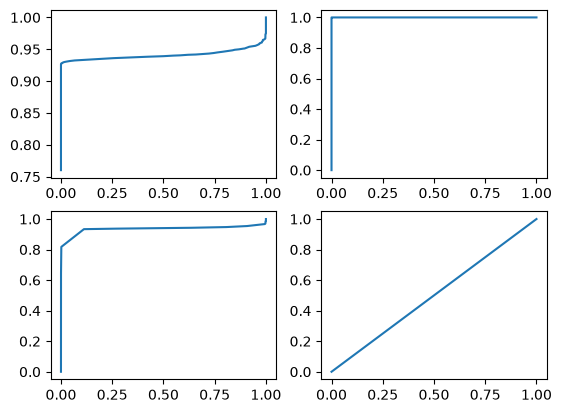

In [195]:
# Exercise 2.c
import matplotlib.pyplot as plt
# Plot the FDR/TPR-curves with the TPR on the horizontal axis and the FDR on the vertical axis,
# and compute the AUC of each plotted curve on the test data.
# Thresholds c: you may use all distinct predicted probabilities (this gives the exact curve), or a grid of
# values in [0, 1]. A uniform grid such as np.linspace(0, 1, 100) can be too coarse when many predicted
# probabilities are very close to 1. Check that your curve covers TPR values from (close to) 0 to 1.

# To approximately calculate the AUC, it is fine to simply use Riemann sums.
# This means, if you have N (a_i, b_i) pairs for the curves, ordered such that a_1 <= a_2 <= ... <= a_N,
# then you may simply use the sum
# sum_{i=1}^{N-1} (b_i + b_{i+1})/2 * (a_{i+1}-a_i)
# as the approximation of the integral (or AUC)

def compute_fdr_tpr(y_true, y_pred, ax):
    a = np.linspace(0, n-1, 1000, dtype=int)
    a = np.sort(y1_pred_log[m:, 1])[a]

    n_tp = np.array([np.count_nonzero(y_true[m:]*(c <= y_pred[m:,1])) for c in a])
    n_fp = np.array([np.count_nonzero((1-y_true[m:])*(c <= y_pred[m:,1])) for c in a])
    n_tn = np.array([np.count_nonzero(y_true[m:]*(c > y_pred[m:,1])) for c in a])
    n_fn = np.array([np.count_nonzero((1-y_true[m:])*(c > y_pred[m:,1])) for c in a])

    # Calculate FDR and TPR rate (points on the FDR/TPR curve) and the AUC
    tpr = n_tp/(n_tp + n_fn)
    fpr = n_fp/(n_fp + n_tn)

    ax.plot(fpr, tpr)

    auc = np.sum((tpr[:999]+tpr[1:])/2 * (fpr[:999]-fpr[1:]))

    return auc
    

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)    

# first data set & logistic regression:
# (the code should be reusable for all cases, only exchanging datasets and predicted probabilities depending on the model)
print(f'Dataset 1 with logistic regression: {compute_fdr_tpr(y1, y1_pred_log, ax1)}')

# second data set & logistic regression:
print(f'Dataset 2 with logistic regression: {compute_fdr_tpr(y2, y2_pred_log, ax2)}')

# first data set and SVM:
print(f'Dataset 1 with SVC: {compute_fdr_tpr(y1, y1_pred_svc, ax3)}')

# second data set and SVM:
print(f'Dataset 2 with SVC: {compute_fdr_tpr(y2, y2_pred_svc, ax4)}')

fig.show()

# Print the AUC values.
# Briefly explain (in a Markdown cell or comments) how you construct the curves, interpret what
# the AUC means in this setting, and compare the two models on both data sets.

In [ ]:
# Exercise 3.

# Set model parameters and define matrix D
# (D has n x 50000 = 5*10^8 entries: a float64 array of uniforms of this size needs about 4 GB of memory.
#  If your machine runs out of memory, consider generating D in blocks of columns and/or storing it as booleans.)


# Strategy (i):
# Define Portfolio and possible outcomes for this portfolio using matrix D


# Plot histogram of profits and losses


# Calculate expected profit and losses and 95%-VaR


# Strategy (ii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the logistic regression model


# Plot histogram of profits and losses


# Calculate expected profit and losses and 95%-VaR


# Strategy (iii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the SVM model
# (evaluated on the normalized test features x~_i, see the assignment)


# Plot histogram of profits & losses (which is simply the performance of each strategy in scenario k, i.e. a profit if positive or a loss if negative)


# Calculate and print the expected profit & loss and 95%-VaR for each strategy (in CHF)


# c) Compare the three strategies and briefly interpret your results (Markdown cell or comments).

### Project Report

At the end of the notebook, provide a concise synthesis of your analysis. Do not simply repeat every answer above.

#### Approach
Briefly summarize how you generated the data, which models you fitted, and how you evaluated them and the lending strategies.

#### Model selection
Explain which classifier you would rely on for the lending decision and why. (The model hyperparameters are fixed by the assignment; no hyperparameter tuning is required.)

#### Key results
Summarize the most important quantitative results.

#### Interpretation
Explain what the results imply about the classification methods and the lending problem.

#### Robustness
Discuss how strongly your conclusions could depend on random elements of the analysis (e.g. simulation noise in the data and in the market scenarios). No additional experiments are required.

#### Limitations
State the main limitations of the analysis, the models, and the modelling assumptions.